# Car License Plate Recognition: PP-OCRv5 vs PP-OCRv4 (Training)

Fine-tunes **PP-OCRv5_server_rec** and **PP-OCRv4_server_rec** on Indian licence-plate crops, then visualises training, evaluates, exports and compares both models. The exported models are used by `PPOCR_License_Plate_Inference.ipynb`.

**How to run:** Runtime → Change runtime type → **T4 GPU**, then *Run all* (about 45 minutes, mostly the two training runs). Everything persistent is written to your Google Drive under `MyDrive/award/`, so run this notebook before the inference notebook, with the same Google account.

**Dataset (source and methodology):**
- Source: Kaggle [*Indian vehicle dataset*](https://www.kaggle.com/datasets/saisirishan/indian-vehicle-dataset) (`saisirishan/indian-vehicle-dataset`): car photos with Pascal VOC XML files giving each plate's box **and its text**. Downloaded automatically in section 2.
- We use the `google_images` subset (440 annotations) and build our own recognition dataset from it: remove duplicates → normalise labels (uppercase, A–Z/0–9) → keep valid Indian plate patterns with a real state code → keep readable single-row plates (≥ 80×22 px, aspect 2.5–7) → drop low-contrast crops → rank by sharpness (Laplacian variance) → one image per plate number (prevents train/val leakage) → crop with padding → 100 sharpest plates, shuffled, **80 train / 20 val**.
- Labels are written in PPOCR recognition format: `train/IN_001.png<TAB>MH12AB1234`.
- Licence: the source is CC BY-NC-ND, so the images are not redistributed; the notebook downloads them from Kaggle.

| Section | Contents |
|---|---|
| 1 | Setup: GPU check, PaddlePaddle, PaddleOCR |
| 2 | Dataset: download, filter, crop, 80/20 split, label files |
| 3 | Models: build training configs, download pretrained weights, baseline |
| 4 | Training: fine-tune v5 and v4 with identical settings |
| 5 | Evaluation: baseline vs fine-tuned on the validation set |
| 6 | Visualization: loss and accuracy curves |
| 7 | Error analysis on the validation set |
| 8 | Export to inference format |
| 9 | Comparison and summary |

## 1. Setup

In [1]:
# 1.1 Check the GPU
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv
print("\u2705 Done: 1.1 Check the GPU")  # _STEP_DONE

name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07
✅ Done: 1.1 Check the GPU


In [2]:
# 1.2 Install PaddlePaddle (GPU build for CUDA 12.6)
!python -m pip install -q paddlepaddle-gpu==3.2.0 -i https://www.paddlepaddle.org.cn/packages/stable/cu126/
print("\u2705 Done: 1.2 Install PaddlePaddle (GPU build for CUDA 12.6)")  # _STEP_DONE

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 GB 801.5 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 5.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 9.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.7/897.7 kB 9.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 9.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 571.0/571.0 MB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 393.1/393.1 MB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.2/200.2 MB 5.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 6.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 158.2/158.2 MB 5.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.6/216.6 MB 1.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 156.8/156.8 MB 5.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [3]:
# 1.3 Verify Paddle sees the GPU
import paddle
paddle.utils.run_check()
print(paddle.__version__, paddle.device.is_compiled_with_cuda(), paddle.device.get_device())
print("\u2705 Done: 1.3 Verify Paddle sees the GPU")  # _STEP_DONE

/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


Running verify PaddlePaddle program ... 


/usr/local/lib/python3.13/dist-packages/paddle/pir/math_op_patch.py:219: UserWarning: Value do not have 'place' interface for pir graph mode, try not to use it. None will be returned.
  warnings.warn(


PaddlePaddle works well on 1 GPU.
PaddlePaddle is installed successfully! Let's start deep learning with PaddlePaddle now.
3.2.0 True gpu:0
✅ Done: 1.3 Verify Paddle sees the GPU


In [4]:
# 1.4 Clone PaddleOCR (training code + configs) and install its requirements
!git clone --depth 1 https://github.com/PaddlePaddle/PaddleOCR.git /content/PaddleOCR
%cd /content/PaddleOCR
!pip install -r requirements.txt -q
!ls /content/PaddleOCR/configs/rec | head -20
print("\u2705 Done: 1.4 Clone PaddleOCR (training code + configs) and install its requirem")  # _STEP_DONE

Cloning into '/content/PaddleOCR'...
remote: Enumerating objects: 2912, done.
remote: Counting objects: 100% (2912/2912), done.
remote: Compressing objects: 100% (2087/2087), done.
remote: Total 2912 (delta 777), reused 2580 (delta 729), pack-reused 0 (from 0)
Receiving objects: 100% (2912/2912), 96.60 MiB | 14.68 MiB/s, done.
Resolving deltas: 100% (777/777), done.
Updating files: 100% (2455/2455), done.
/content/PaddleOCR
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.1/572.1 kB 44.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 80.3 MB/s eta 0:00:00
ch_PP-OCRv2
ch_ppocr_v2.0
LaTeX_OCR_rec.yaml
multi_language
PP-FormuaNet
PP-OCRv3
PP-OCRv4
PP-OCRv5
PP-OCRv6
rec_d28_can.yml
rec_efficientb3_fpn_pren.yml
rec_icdar15_train.yml
rec_mtb_nrtr.yml
rec_mv3_none_bilstm_ctc.yml
rec_mv3_none_none_ctc.yml
rec_mv3_tps_bilstm_att.yml
rec_mv3_tps_bilstm_ctc.yml
rec_r31_robustscanner.yml
rec_r3

## 2. Dataset
Download the raw data (once; it is kept on Drive), filter it and build the 100-plate recognition dataset. Expected counts are in the comments; each cell prints what it kept and why the rest was dropped.

### 2.0 Mount Drive and set paths

In [8]:
# 2.0 Mount Drive and set paths
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
PROJECT_ROOT = Path('/content/drive/MyDrive/award')
RAW_DIR      = PROJECT_ROOT / 'raw_dataset'
DATASET_DIR  = PROJECT_ROOT / 'dataset'
OUTPUT_DIR   = PROJECT_ROOT / 'output'
for d in (RAW_DIR, DATASET_DIR, OUTPUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

print('RAW_DIR    :', RAW_DIR, '| exists:', RAW_DIR.exists())
print('DATASET_DIR:', DATASET_DIR)
print('google_images folder exists:', (RAW_DIR / 'google_images').exists())
print("\u2705 Done: 2.0 Mount Drive and set paths")  # _STEP_DONE

Mounted at /content/drive
RAW_DIR    : /content/drive/MyDrive/award/raw_dataset | exists: True
DATASET_DIR: /content/drive/MyDrive/award/dataset
google_images folder exists: False
✅ Done: 2.0 Mount Drive and set paths


### 2.1 Download dataset (only if raw_dataset is empty)

In [9]:
# 2.1 Download dataset (only if raw_dataset is empty)
!pip install -q kagglehub
import kagglehub, shutil
if any(RAW_DIR.iterdir()):
    print('Raw dataset already on Drive, skipping download.')
else:
    src = kagglehub.dataset_download('saisirishan/indian-vehicle-dataset')
    shutil.copytree(src, RAW_DIR, dirs_exist_ok=True)
    print('Copied to', RAW_DIR)
print("\u2705 Done: 2.1 Download dataset (only if raw_dataset is empty)")  # _STEP_DONE

Using Colab cache for faster access to the 'indian-vehicle-dataset' dataset.
Copied to /content/drive/MyDrive/award/raw_dataset
✅ Done: 2.1 Download dataset (only if raw_dataset is empty)


### 2.2 List XML annotations in google_images

In [10]:
# 2.2 List XML annotations in google_images
google_dir = RAW_DIR / 'google_images'
google_xmls = sorted(google_dir.glob('*.xml'))
print('Folder:', google_dir)
print('XML files:', len(google_xmls))   # expect 440
print("\u2705 Done: 2.2 List XML annotations in google_images")  # _STEP_DONE

Folder: /content/drive/MyDrive/award/raw_dataset/google_images
XML files: 440
✅ Done: 2.2 List XML annotations in google_images


### 2.3 Remove duplicates / missing images / incomplete XML

In [11]:
# 2.3 Remove duplicates / missing images / incomplete XML
import xml.etree.ElementTree as ET

def get_img(xml_p):
    for ext in ['.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG']:
        p = xml_p.with_suffix(ext)
        if p.exists():
            return p
    return None

valid_pairs = []
dropped = {'duplicates': 0, 'missing_image': 0, 'incomplete_xml': 0}
for xml_p in google_xmls:
    if '- Copy' in xml_p.name:
        dropped['duplicates'] += 1
        continue
    img_p = get_img(xml_p)
    if not img_p:
        dropped['missing_image'] += 1
        continue
    try:
        obj = ET.parse(xml_p).find('object')
        name = obj.find('name').text if obj is not None else None
        b = obj.find('bndbox') if obj is not None else None
        coords = [int(float(b.find(k).text)) for k in ['xmin', 'ymin', 'xmax', 'ymax']] if b is not None else None
        if not name or not coords:
            dropped['incomplete_xml'] += 1
            continue
        valid_pairs.append({'xml': xml_p, 'img': img_p, 'label': name.strip(), 'box': coords})
    except Exception:
        dropped['incomplete_xml'] += 1

print('Dropped:', dropped)
print('Valid pairs:', len(valid_pairs))   # expect ~428
print("\u2705 Done: 2.3 Remove duplicates / missing images / incomplete XML")  # _STEP_DONE

Dropped: {'duplicates': 12, 'missing_image': 0, 'incomplete_xml': 0}
Valid pairs: 428
✅ Done: 2.3 Remove duplicates / missing images / incomplete XML


### 2.4 Keep only valid Indian plate patterns

In [12]:
# 2.4 Keep only valid Indian plate patterns
import re
VALID_STATES = {
 'AN','AP','AR','AS','BR','CG','CH','DD','DH','DL','DN','GA','GJ','HP','HR','JH','JK','KA','KL','LA','LD','MH',
 'ML','MN','MP','MZ','NL','OD','OR','PB','PY','RJ','SK','TN','TR','TS','UK','UP','WB'}
PLATE_PATTERN = re.compile(r'^[A-Z]{2}[0-9]{2}[A-Z]{0,3}[0-9]{4}$')

pattern_valid_pairs, junk_labels = [], []
for item in valid_pairs:
    norm = re.sub(r'[^A-Z0-9]', '', item['label'].upper())
    if PLATE_PATTERN.match(norm) and norm[:2] in VALID_STATES:
        pattern_valid_pairs.append({**item, 'label': norm})
    else:
        junk_labels.append(item['label'])

print('Valid plates:', len(pattern_valid_pairs), '| junk dropped:', len(junk_labels))  # expect 352 / 766
print('Sample:', [p['label'] for p in pattern_valid_pairs[:5]])
print("\u2705 Done: 2.4 Keep only valid Indian plate patterns")  # _STEP_DONE

Valid plates: 352 | junk dropped: 76
Sample: ['TN21AT0492', 'RJ27TC0530', 'MH20CS9817', 'KL05AK3300', 'MP09CP9052']
✅ Done: 2.4 Keep only valid Indian plate patterns


### 2.5 Size + single-row filter

In [13]:
# 2.5 Size + single-row filter
size_valid_pairs = []
dropped_size = {'too_small': 0, 'two_row_or_bad_ratio': 0}
for item in pattern_valid_pairs:
    xmin, ymin, xmax, ymax = item['box']
    w, h = xmax - xmin, ymax - ymin
    if w < 80 or h < 22:
        dropped_size['too_small'] += 1
        continue
    ar = w / float(h)
    if not (2.5 <= ar <= 7.0):
        dropped_size['two_row_or_bad_ratio'] += 1
        continue
    size_valid_pairs.append({**item, 'width': w, 'height': h, 'ar': round(ar, 2)})

print('Dropped:', dropped_size)
print('Remaining:', len(size_valid_pairs))   # expect 276
print("\u2705 Done: 2.5 Size + single-row filter")  # _STEP_DONE

Dropped: {'too_small': 35, 'two_row_or_bad_ratio': 41}
Remaining: 276
✅ Done: 2.5 Size + single-row filter


### 2.6 Contrast filter + sharpness score

In [14]:
# 2.6 Contrast filter + sharpness score
import cv2, numpy as np

def compute_sharpness(gray):
    h, w = gray.shape[:2]
    if h == 0 or w == 0:
        return 0.0
    scale = 48.0 / h
    resized = cv2.resize(gray, (max(1, int(w * scale)), 48), interpolation=cv2.INTER_AREA)
    return float(cv2.Laplacian(resized, cv2.CV_64F).var())

quality_valid_pairs, dropped_contrast = [], 0
for item in size_valid_pairs:
    xmin, ymin, xmax, ymax = item['box']
    img = cv2.imread(str(item['img']))
    if img is None:
        continue
    crop = img[ymin:ymax, xmin:xmax]
    if crop.size == 0:
        continue
    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    contrast = float(np.std(gray))
    if contrast < 20.0:
        dropped_contrast += 1
        continue
    quality_valid_pairs.append({**item, 'contrast': round(contrast, 2),
                                'sharpness': round(compute_sharpness(gray), 2)})

quality_valid_pairs.sort(key=lambda x: x['sharpness'], reverse=True)
print('Low-contrast dropped:', dropped_contrast, '| remaining:', len(quality_valid_pairs))  # expect 275
print("\u2705 Done: 2.6 Contrast filter + sharpness score")  # _STEP_DONE

Low-contrast dropped: 1 | remaining: 275
✅ Done: 2.6 Contrast filter + sharpness score


### 2.7 One crop per unique plate (sharpest first)

In [15]:
# 2.7 One crop per unique plate (sharpest first)
seen, unique_plates = set(), []
for item in quality_valid_pairs:
    if item['label'] not in seen:
        seen.add(item['label'])
        unique_plates.append(item)
print('Unique plates:', len(unique_plates))   # expect 134
print("\u2705 Done: 2.7 One crop per unique plate (sharpest first)")  # _STEP_DONE

Unique plates: 134
✅ Done: 2.7 One crop per unique plate (sharpest first)


### 2.8 Export crops + manifest to Drive

In [16]:
# 2.8 Export crops + manifest to Drive
import csv, cv2
out_dir = DATASET_DIR
crops_dir = out_dir / 'crops'
crops_dir.mkdir(parents=True, exist_ok=True)

manifest = []
for idx, item in enumerate(unique_plates):
    img = cv2.imread(str(item['img']))
    h_img, w_img = img.shape[:2]
    xmin, ymin, xmax, ymax = item['box']
    pw, ph = int(0.04 * (xmax - xmin)), int(0.12 * (ymax - ymin))
    x1, y1 = max(0, xmin - pw), max(0, ymin - ph)
    x2, y2 = min(w_img, xmax + pw), min(h_img, ymax + ph)
    name = f'IN_{idx + 1:03d}.png'
    cv2.imwrite(str(crops_dir / name), img[y1:y2, x1:x2])
    manifest.append({'filename': name, 'label': item['label'], 'sharpness': item['sharpness'],
                     'contrast': item['contrast'], 'source_img': Path(item['img']).name})

with open(out_dir / 'candidates_manifest.csv', 'w', newline='', encoding='utf-8') as f:
    w = csv.DictWriter(f, fieldnames=['filename', 'label', 'sharpness', 'contrast', 'source_img'])
    w.writeheader()
    w.writerows(manifest)

print('Crops saved:', len(manifest), 'in', crops_dir)
print("\u2705 Done: 2.8 Export crops + manifest to Drive")  # _STEP_DONE

Crops saved: 134 in /content/drive/MyDrive/award/dataset/crops
✅ Done: 2.8 Export crops + manifest to Drive


### 2.9 Split train/val and write PaddleOCR label files

In [17]:
# 2.9 Split train/val and write PaddleOCR label files
import random, shutil

google_dir = RAW_DIR / 'google_images'
train_crop_dir, val_crop_dir = out_dir / 'train', out_dir / 'val'
full_train_dir = out_dir / 'full_images' / 'train'
full_val_dir   = out_dir / 'full_images' / 'val'
full_ann_dir   = out_dir / 'full_images' / 'annotations'
for d in (train_crop_dir, val_crop_dir, full_train_dir, full_val_dir, full_ann_dir):
    d.mkdir(parents=True, exist_ok=True)

with open(out_dir / 'candidates_manifest.csv', encoding='utf-8') as f:
    manifest_lookup = {r['filename']: r for r in csv.DictReader(f)}

# 100 sharpest, shuffled so train and val have the same quality mix
names = sorted(n for n in manifest_lookup if (crops_dir / n).exists())[:100]
random.Random(42).shuffle(names)
train_names, val_names = names[:80], names[80:100]

counts = {'full_img': 0, 'xml': 0}
def process_split(names, crop_dir, full_dir, split):
    lines = []
    for n in names:
        info = manifest_lookup[n]
        shutil.copy2(crops_dir / n, crop_dir / n)
        src_img = google_dir / info['source_img']
        if src_img.exists():
            shutil.copy2(src_img, full_dir / f'{Path(n).stem}{src_img.suffix.lower()}')
            counts['full_img'] += 1
        src_xml = google_dir / (src_img.stem + '.xml')
        if src_xml.exists():
            shutil.copy2(src_xml, full_ann_dir / f'{Path(n).stem}.xml')
            counts['xml'] += 1
        lines.append(f"{split}/{n}\t{info['label']}\n")
    return lines

train_gt = process_split(train_names, train_crop_dir, full_train_dir, 'train')
val_gt   = process_split(val_names,   val_crop_dir,   full_val_dir,   'val')
(out_dir / 'rec_gt_train.txt').write_text(''.join(train_gt), encoding='utf-8')
(out_dir / 'rec_gt_val.txt').write_text(''.join(val_gt), encoding='utf-8')

print('Output dir:', out_dir)
print('Train crops:', len(list(train_crop_dir.glob('*.png'))), '| Val crops:', len(list(val_crop_dir.glob('*.png'))))
print('Full images copied:', counts['full_img'], '| XMLs copied:', counts['xml'])
print('GT train:', len(train_gt), repr(train_gt[0].strip()))
print('GT val:  ', len(val_gt), repr(val_gt[0].strip()))
print("\u2705 Done: 2.9 Split train/val and write PaddleOCR label files")  # _STEP_DONE

Output dir: /content/drive/MyDrive/award/dataset
Train crops: 80 | Val crops: 20
Full images copied: 100 | XMLs copied: 100
GT train: 80 'train/IN_043.png\tMH12JC2813'
GT val:   20 'val/IN_065.png\tMH06AW8929'
✅ Done: 2.9 Split train/val and write PaddleOCR label files


## 3. Models: configs, pretrained weights, baseline
Both models start from the official `*_server_rec` configs and pretrained weights, with **identical** settings so the comparison is fair: 80 epochs, batch 16, learning rate 1e-4 with cosine decay and 2 warm-up epochs, evaluation every 25 steps. Each model keeps its **original dictionary** (changing it would resize the output layer and discard pretrained knowledge). Data is copied to Colab's local disk for fast reading.

In [18]:
# 3.1 Copy the dataset to local disk and build the v5 + v4 training configs (identical settings)
import yaml, os, shutil
from pathlib import Path

PADDLEOCR_DIR = "/content/PaddleOCR"
LOCAL_DATA = Path("/content/dataset")
for sub in ("train", "val"):
    shutil.copytree(DATASET_DIR / sub, LOCAL_DATA / sub, dirs_exist_ok=True)
for f in ("rec_gt_train.txt", "rec_gt_val.txt"):
    shutil.copy2(DATASET_DIR / f, LOCAL_DATA / f)
print("Local data:", sorted(os.listdir(LOCAL_DATA)))

BASES = {
    "v5": f"{PADDLEOCR_DIR}/configs/rec/PP-OCRv5/PP-OCRv5_server_rec.yml",
    "v4": f"{PADDLEOCR_DIR}/configs/rec/PP-OCRv4/PP-OCRv4_server_rec.yml",
}

def build_cfg(tag, base_path):
    cfg = yaml.safe_load(open(base_path))
    g = cfg["Global"]
    g["use_gpu"] = True
    g["epoch_num"] = 80
    g["save_model_dir"] = f"/content/output/rec_{tag}"
    g["save_epoch_step"] = 10
    g["eval_batch_step"] = [0, 25]
    g["print_batch_step"] = 5
    # dictionary deliberately NOT changed (each model keeps its original)
    for split, lab in (("Train", "rec_gt_train.txt"), ("Eval", "rec_gt_val.txt")):
        cfg[split]["dataset"]["data_dir"] = str(LOCAL_DATA)
        cfg[split]["dataset"]["label_file_list"] = [str(LOCAL_DATA / lab)]
    cfg["Train"]["loader"]["batch_size_per_card"] = 16
    cfg["Train"]["loader"]["num_workers"] = 2
    cfg["Eval"]["loader"]["batch_size_per_card"] = 16
    cfg["Eval"]["loader"]["num_workers"] = 2
    if "sampler" in cfg["Train"] and "first_bs" in cfg["Train"]["sampler"]:
        cfg["Train"]["sampler"]["first_bs"] = 16
    cfg["Optimizer"]["lr"]["learning_rate"] = 1e-4
    out = Path(f"/content/output/plate_rec_{tag}.yml")
    out.parent.mkdir(parents=True, exist_ok=True)
    yaml.safe_dump(cfg, open(out, "w"), sort_keys=False)
    print(f"[{tag}] {out} | dict: {g.get('character_dict_path')} | lr: {cfg['Optimizer']['lr']}")
    return out

CFG = {tag: build_cfg(tag, p) for tag, p in BASES.items()}
print("\u2705 Done: 3.1 Copy the dataset to local disk and build the v5 + v4 training conf")  # _STEP_DONE

Local data: ['rec_gt_train.txt', 'rec_gt_val.txt', 'train', 'val']
[v5] /content/output/plate_rec_v5.yml | dict: ./ppocr/utils/dict/ppocrv5_dict.txt | lr: {'name': 'Cosine', 'learning_rate': 0.0001, 'warmup_epoch': 1}
[v4] /content/output/plate_rec_v4.yml | dict: ppocr/utils/ppocr_keys_v1.txt | lr: {'name': 'Cosine', 'learning_rate': 0.0001, 'warmup_epoch': 5}
✅ Done: 3.1 Copy the dataset to local disk and build the v5 + v4 training conf


In [19]:
# 3.2 Download the official pretrained weights and set an identical warm-up (2 epochs)
import os, re, glob, subprocess, yaml
from pathlib import Path

PADDLEOCR_DIR = "/content/PaddleOCR"
STD_URL = "https://paddle-model-ecology.bj.bcebos.com/paddlex/official_pretrained_model/{m}_pretrained.pdparams"
MODELS = {"v5": "PP-OCRv5_server_rec", "v4": "PP-OCRv4_server_rec"}
WARMUP = 2

def find_url(model):
    # search the repo docs for the official link
    out = subprocess.run(["grep", "-rhoE", rf"https?://[^ )\"'>]*{model}_pretrained\.pdparams",
                          f"{PADDLEOCR_DIR}/docs"], capture_output=True, text=True).stdout.split()
    return out[0] if out else STD_URL.format(m=model)

for tag, model in MODELS.items():
    url = find_url(model)
    dst = Path(f"/content/output/pretrained/{model}_pretrained.pdparams")
    dst.parent.mkdir(parents=True, exist_ok=True)
    if not dst.exists() or dst.stat().st_size < 1_000_000:
        os.system(f'wget -q -O "{dst}" "{url}"')
    size_mb = dst.stat().st_size / 1e6 if dst.exists() else 0
    ok = size_mb > 1
    print(f"[{tag}] {url}\n      -> {dst}  ({size_mb:.1f} MB)  {'OK' if ok else 'DOWNLOAD FAILED'}")

    cfg_path = f"/content/output/plate_rec_{tag}.yml"
    cfg = yaml.safe_load(open(cfg_path))
    if ok:
        cfg["Global"]["pretrained_model"] = str(dst.with_suffix(""))   # path without .pdparams
    cfg["Optimizer"]["lr"]["warmup_epoch"] = WARMUP
    yaml.safe_dump(cfg, open(cfg_path, "w"), sort_keys=False)
    print(f"      config: pretrained={cfg['Global']['pretrained_model']} | lr={cfg['Optimizer']['lr']}")
print("\u2705 Done: 3.2 Download the official pretrained weights and set an identical warm")  # _STEP_DONE

[v5] https://paddle-model-ecology.bj.bcebos.com/paddlex/official_pretrained_model/PP-OCRv5_server_rec_pretrained.pdparams
      -> /content/output/pretrained/PP-OCRv5_server_rec_pretrained.pdparams  (214.6 MB)  OK
      config: pretrained=/content/output/pretrained/PP-OCRv5_server_rec_pretrained | lr={'name': 'Cosine', 'learning_rate': 0.0001, 'warmup_epoch': 2}
[v4] https://paddle-model-ecology.bj.bcebos.com/paddlex/official_pretrained_model/PP-OCRv4_server_rec_pretrained.pdparams
      -> /content/output/pretrained/PP-OCRv4_server_rec_pretrained.pdparams  (158.0 MB)  OK
      config: pretrained=/content/output/pretrained/PP-OCRv4_server_rec_pretrained | lr={'name': 'Cosine', 'learning_rate': 0.0001, 'warmup_epoch': 2}
✅ Done: 3.2 Download the official pretrained weights and set an identical warm


### 3.3 Baseline: pretrained weights on the validation set, before any training

In [20]:
# 3.3 Baseline: evaluate pretrained weights on val (no training yet)
%cd /content/PaddleOCR
for tag in ("v5", "v4"):
    print(f"\n===== BASELINE {tag} =====")
    !python tools/eval.py -c /content/output/plate_rec_{tag}.yml
print("\u2705 Done: 3.3 Baseline: evaluate pretrained weights on val (no training yet)")  # _STEP_DONE

/content/PaddleOCR

===== BASELINE v5 =====
/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Skipping import of the encryption module.
[2026/10/09 11:23:18] ppocr INFO: Architecture : 
[2026/10/09 11:23:18] ppocr INFO:     Backbone : 
[2026/10/09 11:23:18] ppocr INFO:         name : PPHGNetV2_B4
[2026/10/09 11:23:18] ppocr INFO:         text_rec : True
[2026/10/09 11:23:18] ppocr INFO:     Head : 
[2026/10/09 11:23:18] ppocr INFO:         head_list : 
[2026/10/09 11:23:18] ppocr INFO:             CTCHead : 
[2026/10/09 11:23:18] ppocr INFO:                 Head : 
[2026/10/09 11:23:18] ppocr INFO:                     fc_decay : 1e-05
[2026/10/09 11:23:18] ppocr INFO:                 Neck : 
[2026/10/09 11:23:18] ppoc

## 4. Training
Fine-tune each model for 80 epochs (720 steps). The best checkpoint on the validation set is kept as `best_accuracy`; logs are saved for the curves in section 6. Each run takes roughly 20 minutes on a T4.

In [21]:
# 4.1 Fine-tune PP-OCRv5_server_rec
tag = "v5"
%cd /content/PaddleOCR
!python tools/train.py -c /content/output/plate_rec_{tag}.yml 2>&1 | tee /content/output/train_{tag}.log
print("\u2705 Done: 4.1 Fine-tune PP-OCRv5_server_rec")  # _STEP_DONE

/content/PaddleOCR
/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Skipping import of the encryption module.
[2026/10/09 11:23:57] ppocr INFO: Architecture : 
[2026/10/09 11:23:57] ppocr INFO:     Backbone : 
[2026/10/09 11:23:57] ppocr INFO:         name : PPHGNetV2_B4
[2026/10/09 11:23:57] ppocr INFO:         text_rec : True
[2026/10/09 11:23:57] ppocr INFO:     Head : 
[2026/10/09 11:23:57] ppocr INFO:         head_list : 
[2026/10/09 11:23:57] ppocr INFO:             CTCHead : 
[2026/10/09 11:23:57] ppocr INFO:                 Head : 
[2026/10/09 11:23:57] ppocr INFO:                     fc_decay : 1e-05
[2026/10/09 11:23:57] ppocr INFO:                 Neck : 
[2026/10/09 11:23:57] ppocr INFO:                  

In [22]:
# 4.2 Fine-tune PP-OCRv4_server_rec
tag = "v4"
%cd /content/PaddleOCR
!python tools/train.py -c /content/output/plate_rec_{tag}.yml 2>&1 | tee /content/output/train_{tag}.log
print("\u2705 Done: 4.2 Fine-tune PP-OCRv4_server_rec")  # _STEP_DONE

/content/PaddleOCR
/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Skipping import of the encryption module.
[2026/10/09 11:40:05] ppocr INFO: Architecture : 
[2026/10/09 11:40:05] ppocr INFO:     Backbone : 
[2026/10/09 11:40:05] ppocr INFO:         name : PPHGNet_small
[2026/10/09 11:40:05] ppocr INFO:     Head : 
[2026/10/09 11:40:05] ppocr INFO:         head_list : 
[2026/10/09 11:40:05] ppocr INFO:             CTCHead : 
[2026/10/09 11:40:05] ppocr INFO:                 Head : 
[2026/10/09 11:40:05] ppocr INFO:                     fc_decay : 1e-05
[2026/10/09 11:40:05] ppocr INFO:                 Neck : 
[2026/10/09 11:40:05] ppocr INFO:                     depth : 2
[2026/10/09 11:40:05] ppocr INFO:           

### 4.3 Save checkpoints, logs and configs to Drive (Colab's local disk is wiped when the session ends)

In [23]:
# 4.3 Save checkpoints, logs and configs to Drive (Colab's local disk is wiped when the session ends)
!mkdir -p "{OUTPUT_DIR}"
!cp -r /content/output/rec_v5 /content/output/rec_v4 /content/output/*.log /content/output/*.yml "{OUTPUT_DIR}/"
!ls "{OUTPUT_DIR}"
print("\u2705 Done: 4.3 Save checkpoints, logs and configs to Drive (Colab's local disk is")  # _STEP_DONE

plate_rec_v4.yml  plate_rec_v5.yml  rec_v4  rec_v5  train_v4.log  train_v5.log
✅ Done: 4.3 Save checkpoints, logs and configs to Drive (Colab's local disk is


## 5. Evaluation
Validation set (20 plates), **before** (official pretrained weights) vs **after** fine-tuning.
- `acc`: the whole plate read exactly right
- `norm_edit_dis`: character-level similarity (1.0 = perfect)
- `acc_gain_plates`: change in correctly read plates out of 20 (each plate = 5 points)

In [24]:
# 5.1 Evaluation: baseline vs fine-tuned for both models
import re, subprocess, os
import pandas as pd

os.chdir("/content/PaddleOCR")

def run_eval(cfg, weights=None):
    cmd = ["python", "tools/eval.py", "-c", cfg]
    if weights:
        cmd += ["-o", f"Global.pretrained_model={weights}"]
    out = subprocess.run(cmd, capture_output=True, text=True).stdout + \
          subprocess.run(["true"], capture_output=True, text=True).stdout
    # the metrics come after "metric eval"
    tail = out.split("metric eval")[-1]
    get = lambda k: float(m.group(1)) if (m := re.search(rf"\b{k}:\s*([\d.]+)", tail)) else float("nan")
    return get("acc"), get("norm_edit_dis"), get("fps")

def dir_mb(path):
    if not os.path.isdir(path):
        return float("nan")
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(path) for f in fs) / 1e6

rows = []
for tag, name in (("v5", "PP-OCRv5_server_rec"), ("v4", "PP-OCRv4_server_rec")):
    cfg = f"/content/output/plate_rec_{tag}.yml"
    b_acc, b_ned, b_fps = run_eval(cfg)                                          # pretrained (from config)
    f_acc, f_ned, f_fps = run_eval(cfg, f"/content/output/rec_{tag}/best_accuracy")  # fine-tuned
    rows.append({
        "model": name,
        "baseline_acc": round(b_acc, 3), "baseline_norm_edit": round(b_ned, 3),
        "finetuned_acc": round(f_acc, 3), "finetuned_norm_edit": round(f_ned, 3),
        "acc_gain_plates": round((f_acc - b_acc) * 20),
        "eval_fps": round(f_fps, 1),
        "export_size_MB": round(dir_mb(f"/content/output/inference/{tag}"), 1),
    })

results = pd.DataFrame(rows)
display(results)
results.to_csv("/content/output/eval_summary.csv", index=False)
!cp /content/output/eval_summary.csv "{OUTPUT_DIR}/"
print("\u2705 Done: 5.1 Evaluation: baseline vs fine-tuned for both models")  # _STEP_DONE

,model,baseline_acc,baseline_norm_edit,finetuned_acc,finetuned_norm_edit,acc_gain_plates,eval_fps,export_size_MB
0,PP-OCRv5_server_rec,0.8,0.911,0.85,0.918,1,28.7,NaN
1,PP-OCRv4_server_rec,0.8,0.913,0.85,0.930,1,24.6,NaN


✅ Done: 5.1 Evaluation: baseline vs fine-tuned for both models


## 6. Visualization: training curves
Training loss, training accuracy and validation accuracy per step for both models; dashed lines are the pretrained baselines from section 5.

v5: 208 train points, 28 eval points, best val acc = 0.850
v4: 208 train points, 28 eval points, best val acc = 0.850


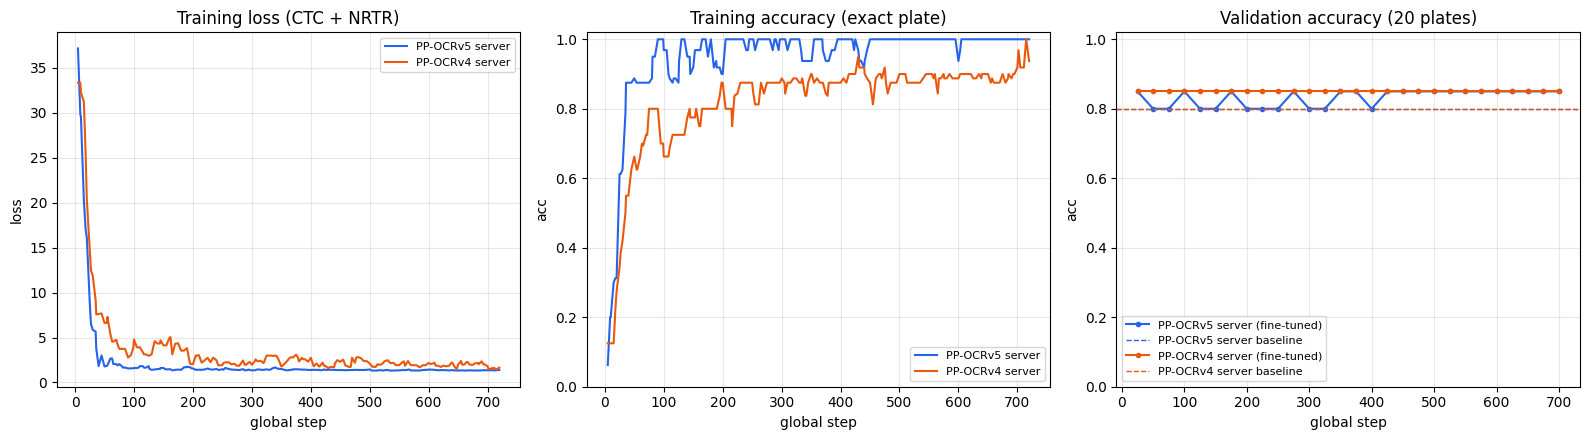

✅ Done: 6.1 Training curves from the logs


In [25]:
# 6.1 Training curves from the logs
import re
import matplotlib.pyplot as plt

COLORS = {"v5": "#2563eb", "v4": "#ea580c"}
LABELS = {"v5": "PP-OCRv5 server", "v4": "PP-OCRv4 server"}

train_re = re.compile(r"global_step: (\d+).*?\bacc: ([\d.]+), norm_edit_dis: ([\d.]+).*?\bloss: ([\d.]+)")
eval_re  = re.compile(r"cur metric, acc: ([\d.]+),(?: is_float16: \w+,)? norm_edit_dis: ([\d.]+)")

def parse_log(path):
    tr, ev, last_step = [], [], 0
    for line in open(path, errors="ignore"):
        if (m := train_re.search(line)):
            last_step = int(m.group(1))
            tr.append((last_step, float(m.group(2)), float(m.group(4))))
        elif (m := eval_re.search(line)):
            ev.append((last_step, float(m.group(1)), float(m.group(2))))
    return tr, ev

logs = {tag: parse_log(f"/content/output/train_{tag}.log") for tag in ("v5", "v4")}
base = {r["model"][:8].replace("PP-OCRv", "v"): r["baseline_acc"] for r in rows} if "rows" in dir() else {}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for tag, (tr, ev) in logs.items():
    c, lab = COLORS[tag], LABELS[tag]
    if tr:
        s, a, l = zip(*tr)
        axes[0].plot(s, l, color=c, label=lab, lw=1.5)
        axes[1].plot(s, a, color=c, label=lab, lw=1.5)
    if ev:
        s, a, _ = zip(*ev)
        axes[2].plot(s, a, color=c, marker="o", ms=3, label=f"{lab} (fine-tuned)", lw=1.5)
    if tag in base:
        axes[2].axhline(base[tag], color=c, ls="--", lw=1, label=f"{lab} baseline")
    print(f"{tag}: {len(tr)} train points, {len(ev)} eval points, "
          f"best val acc = {max((e[1] for e in ev), default=float('nan')):.3f}")

axes[0].set(title="Training loss (CTC + NRTR)", xlabel="global step", ylabel="loss")
axes[1].set(title="Training accuracy (exact plate)", xlabel="global step", ylabel="acc", ylim=(0, 1.02))
axes[2].set(title="Validation accuracy (20 plates)", xlabel="global step", ylabel="acc", ylim=(0, 1.02))
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("/content/output/training_curves.png", dpi=130)
plt.show()
!cp /content/output/training_curves.png "{OUTPUT_DIR}/"
print("\u2705 Done: 6.1 Training curves from the logs")  # _STEP_DONE

## 7. Error analysis on the validation set
Which plates each fine-tuned model reads wrongly, with the crops shown below.

In [26]:
# 7.1 Predict every validation crop with each best checkpoint and list the mistakes
%cd /content/PaddleOCR
for tag in ("v5", "v4"):
    !python tools/infer_rec.py -c /content/output/plate_rec_{tag}.yml \
        -o Global.pretrained_model=/content/output/rec_{tag}/best_accuracy \
           Global.infer_img=/content/dataset/val \
           Global.save_res_path=/content/output/pred_val_{tag}.txt > /dev/null 2>&1

import os, csv

gt = {}
for l in open("/content/dataset/rec_gt_val.txt"):
    k, v = l.rstrip("\n").split("\t")
    gt[os.path.basename(k)] = v

def load_preds(tag):
    preds = {}
    for line in open(f"/content/output/pred_val_{tag}.txt"):
        parts = line.rstrip("\n").split("\t")
        name = os.path.basename(parts[0])
        text = parts[1] if len(parts) > 1 else ""
        conf = float(parts[2]) if len(parts) > 2 else float("nan")
        preds[name] = (text, conf)
    return preds

P = {tag: load_preds(tag) for tag in ("v5", "v4")}

rows = []
for name in sorted(gt):
    t5, c5 = P["v5"].get(name, ("", float("nan")))
    t4, c4 = P["v4"].get(name, ("", float("nan")))
    rows.append([name, gt[name], t5, round(c5, 4), t5 == gt[name], t4, round(c4, 4), t4 == gt[name]])

for tag, ti, oki in (("v5", 2, 4), ("v4", 5, 7)):
    wrong = [r for r in rows if not r[oki]]
    print(f"\n{tag}: {len(rows) - len(wrong)}/{len(rows)} correct, {len(wrong)} wrong")
    for r in wrong:
        print(f"   {r[0]}  gt={r[1]:<11} pred={r[ti]:<11} conf={r[ti+1]}")

with open("/content/output/val_predictions.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["file", "gt", "v5_pred", "v5_conf", "v5_ok", "v4_pred", "v4_conf", "v4_ok"])
    w.writerows(rows)
!cp /content/output/val_predictions.csv "{OUTPUT_DIR}/"
print("\nSaved val_predictions.csv")
print("\u2705 Done: 7.1 Predict every validation crop with each best checkpoint and list t")  # _STEP_DONE

/content/PaddleOCR

v5: 17/20 correct, 3 wrong
   IN_029.png  gt=HR99HA4575  pred=HR9ATEP|4575 conf=0.7745
   IN_070.png  gt=HR99EX6037  pred=HR99EX(TEMP6037 conf=0.9798
   IN_095.png  gt=TN42R2697   pred=278         conf=0.7429

v4: 17/20 correct, 3 wrong
   IN_029.png  gt=HR99HA4575  pred=HR99HATEB74575 conf=0.7826
   IN_070.png  gt=HR99EX6037  pred=HR99EXTEMP)6037 conf=0.9823
   IN_095.png  gt=TN42R2697   pred=L16497      conf=0.5096

Saved val_predictions.csv
✅ Done: 7.1 Predict every validation crop with each best checkpoint and list t


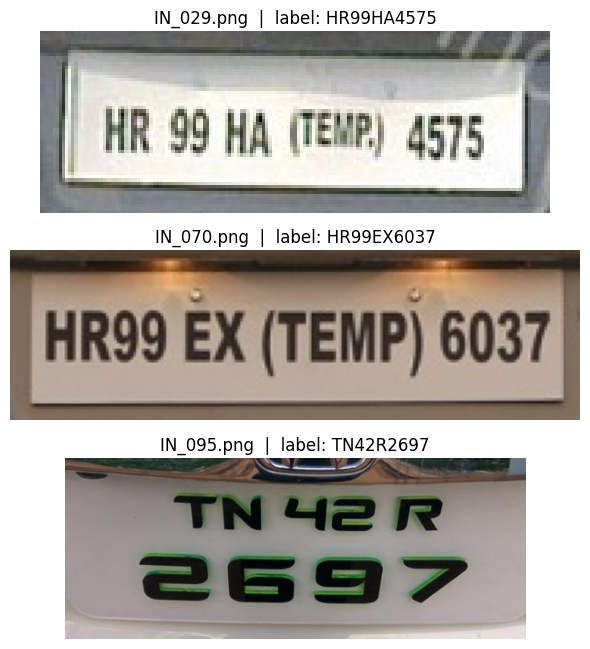

✅ Done: 7.2 Show the failing crops


In [27]:
# 7.2 Show the failing crops
import matplotlib.pyplot as plt
from PIL import Image

fails = [("IN_029.png", "HR99HA4575"), ("IN_070.png", "HR99EX6037"), ("IN_095.png", "TN42R2697")]
fig, axes = plt.subplots(len(fails), 1, figsize=(6, 2.2 * len(fails)))
for ax, (name, gt) in zip(axes, fails):
    ax.imshow(Image.open(f"/content/dataset/val/{name}"))
    ax.set_title(f"{name}  |  label: {gt}")
    ax.axis("off")
plt.tight_layout()
plt.savefig("/content/output/val_failures.png", dpi=120)
plt.show()
!cp /content/output/val_failures.png "{OUTPUT_DIR}/"
print("\u2705 Done: 7.2 Show the failing crops")  # _STEP_DONE

## 8. Export to inference format
Convert each `best_accuracy` checkpoint into an inference model (`inference.json` + `inference.pdiparams` + `inference.yml`), saved to Drive for the inference notebook.

In [28]:
# 8. Export to inference format
%cd /content/PaddleOCR
for tag in ("v5", "v4"):
    !python tools/export_model.py -c /content/output/plate_rec_{tag}.yml \
        -o Global.pretrained_model=/content/output/rec_{tag}/best_accuracy \
           Global.save_inference_dir=/content/output/inference/{tag}
!ls -R /content/output/inference
!cp -r /content/output/inference "{OUTPUT_DIR}/"
print("\u2705 Done: 8. Export to inference format")  # _STEP_DONE

/content/PaddleOCR
/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Skipping import of the encryption module.
W1009 12:02:29.947968 20271 gpu_resources.cc:114] Please NOTE: device: 0, GPU Compute Capability: 7.5, Driver API Version: 13.0, Runtime API Version: 12.6
[2026/10/09 12:02:30] ppocr INFO: load pretrain successful from /content/output/rec_v5/best_accuracy
[2026/10/09 12:02:31] ppocr INFO: Export inference config file to /content/output/inference/v5/inference.yml
Skipping import of the encryption module
W1009 12:02:33.249888 20271 eager_utils.cc:3441] Paddle static graph(PIR) not support input out tensor for now!!!!!
[2026/10/09 12:02:34] ppocr INFO: inference model is saved to /content/output/inference/v5/inf

## 9. Comparison and summary

| | PP-OCRv5_server_rec | PP-OCRv4_server_rec |
|---|---|---|
| Baseline acc (pretrained) | 0.80 (16/20) | 0.80 (16/20) |
| Fine-tuned acc | 0.85 (17/20) | 0.85 (17/20) |
| Fine-tuned norm_edit_dis | 0.918 | 0.922 |
| Train acc at end | ~1.00 | 0.89 |
| GPU memory (training) | 2.6 GB | 1.9 GB |
| Exported size | 84.9 MB | 90.7 MB |

**The two models are tied.** They have the same accuracy before and after fine-tuning and fail on the same three plates; the edit-distance difference is under one character across the whole validation set.

**Fine-tuning helped only marginally.** One extra plate out of 20 is within the noise of a 20-plate validation set. Both pretrained models already read printed alphanumeric plates well.

**Errors come mostly from the data.** Two of the three failures are temporary plates where both models read a printed "TEMP" that the labels leave out; the third (IN_095) is unreadable for both models.

**Training behaviour.** v5 reached ~100% training accuracy while validation stayed at 85% (overfitting on 80 images); v4 was still learning at epoch 80.

**Speed.** The `eval_fps` values include start-up overhead; in the training logs both ran at about 220 img/s on the T4. The inference notebook measures time per image after a warm-up.

**Limitations.** 80/20 plates is small; one training run per model; inference uses annotation boxes rather than a detector.

## Run status
Checks that every output this notebook should produce exists, so a reviewer can confirm the run completed.

In [29]:
# Final run status: confirm every expected output exists
OK, NO = '\u2705', '\u274c'
import os
from pathlib import Path
checks = {
    "Label file (train)":            DATASET_DIR / "rec_gt_train.txt",
    "Label file (val)":              DATASET_DIR / "rec_gt_val.txt",
    "Training config v5":            Path("/content/output/plate_rec_v5.yml"),
    "Training config v4":            Path("/content/output/plate_rec_v4.yml"),
    "Best checkpoint v5":            Path("/content/output/rec_v5/best_accuracy.pdparams"),
    "Best checkpoint v4":            Path("/content/output/rec_v4/best_accuracy.pdparams"),
    "Training log v5":               Path("/content/output/train_v5.log"),
    "Training log v4":               Path("/content/output/train_v4.log"),
    "Training curves figure":        Path("/content/output/training_curves.png"),
    "Evaluation summary":            Path("/content/output/eval_summary.csv"),
    "Exported model v5 (Drive)":     OUTPUT_DIR / "inference" / "v5" / "inference.pdiparams",
    "Exported model v4 (Drive)":     OUTPUT_DIR / "inference" / "v4" / "inference.pdiparams",
}
n_train = sum(1 for _ in open(DATASET_DIR / "rec_gt_train.txt")) if (DATASET_DIR / "rec_gt_train.txt").exists() else 0
n_val   = sum(1 for _ in open(DATASET_DIR / "rec_gt_val.txt")) if (DATASET_DIR / "rec_gt_val.txt").exists() else 0
ok_all = True
for name, p in checks.items():
    ok = p.exists()
    ok_all &= ok
    print(f"{OK if ok else NO}  {name:28} {p}")
print(f"\nDataset: {n_train} train + {n_val} val = {n_train + n_val} images (min. 100 required)")
print("\nALL STEPS COMPLETED" if ok_all else "\nSOME OUTPUTS ARE MISSING - rerun the cells marked above")

✅  Label file (train)           /content/drive/MyDrive/award/dataset/rec_gt_train.txt
✅  Label file (val)             /content/drive/MyDrive/award/dataset/rec_gt_val.txt
✅  Training config v5           /content/output/plate_rec_v5.yml
✅  Training config v4           /content/output/plate_rec_v4.yml
✅  Best checkpoint v5           /content/output/rec_v5/best_accuracy.pdparams
✅  Best checkpoint v4           /content/output/rec_v4/best_accuracy.pdparams
✅  Training log v5              /content/output/train_v5.log
✅  Training log v4              /content/output/train_v4.log
✅  Training curves figure       /content/output/training_curves.png
✅  Evaluation summary           /content/output/eval_summary.csv
✅  Exported model v5 (Drive)    /content/drive/MyDrive/award/output/inference/v5/inference.pdiparams
✅  Exported model v4 (Drive)    /content/drive/MyDrive/award/output/inference/v4/inference.pdiparams

Dataset: 80 train + 20 val = 100 images (min. 100 required)

ALL STEPS COMPLETED
